In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")

In [5]:
fake = pd.read_csv("C:/Users/SAHIL KATVE/Downloads/Fake.csv")

In [6]:
fake['label'] = 1
fake.head()

,title,text,subject,date,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",1
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",1
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",1
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",1
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",1


In [7]:
true = pd.read_csv("C:/Users/SAHIL KATVE/Downloads/True.csv")

In [8]:
true['label'] = 0
true.head()

,title,text,subject,date,label
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017",0
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017",0
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017",0
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017",0
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017",0


In [9]:
df = pd.concat([true, fake]).reset_index(drop=True)
df

,title,text,subject,date,label
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017",0
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017",0
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017",0
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017",0
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017",0
...,...,...,...,...,...
44893,McPain: John McCain Furious That Iran Treated ...,21st Century Wire says As 21WIRE reported earl...,Middle-east,"January 16, 2016",1
44894,JUSTICE? Yahoo Settles E-mail Privacy Class-ac...,21st Century Wire says It s a familiar theme. ...,Middle-east,"January 16, 2016",1
44895,Sunnistan: US and Allied ‘Safe Zone’ Plan to T...,Patrick Henningsen 21st Century WireRemember ...,Middle-east,"January 15, 2016",1
44896,How to Blow $700 Million: Al Jazeera America F...,21st Century Wire says Al Jazeera America will...,Middle-east,"January 14, 2016",1


In [10]:
df['label'].value_counts()

label
1    23481
0    21417
Name: count, dtype: int64

In [11]:
df = df.drop(columns=['subject','date'])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 44898 entries, 0 to 44897
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   title   44898 non-null  str  
 1   text    44898 non-null  str  
 2   label   44898 non-null  int64
dtypes: int64(1), str(2)
memory usage: 110.6 MB


In [12]:
df['detail_text'] = df['title'] + " " + df['text']

In [13]:
df = df[['detail_text','label']]
df

,detail_text,label
0,"As U.S. budget fight looms, Republicans flip t...",0
1,U.S. military to accept transgender recruits o...,0
2,Senior U.S. Republican senator: 'Let Mr. Muell...,0
3,FBI Russia probe helped by Australian diplomat...,0
4,Trump wants Postal Service to charge 'much mor...,0
...,...,...
44893,McPain: John McCain Furious That Iran Treated ...,1
44894,JUSTICE? Yahoo Settles E-mail Privacy Class-ac...,1
44895,Sunnistan: US and Allied ‘Safe Zone’ Plan to T...,1
44896,How to Blow $700 Million: Al Jazeera America F...,1


In [14]:
df.isnull().sum()

detail_text    0
label          0
dtype: int64

In [15]:
print(f"Total Duplicated : {int(df.duplicated().sum())} Rows")
print(f"Percentage of Duplicated : {round((df.duplicated().mean())*100,2)}%")

Total Duplicated : 5793 Rows
Percentage of Duplicated : 12.9%


### Here 13% duplicate value so we can remove it safely.

In [16]:
df = df.drop_duplicates().reset_index(drop=True)

In [18]:
df.duplicated().sum()

np.int64(0)

In [17]:
df

,detail_text,label
0,"As U.S. budget fight looms, Republicans flip t...",0
1,U.S. military to accept transgender recruits o...,0
2,Senior U.S. Republican senator: 'Let Mr. Muell...,0
3,FBI Russia probe helped by Australian diplomat...,0
4,Trump wants Postal Service to charge 'much mor...,0
...,...,...
39100,The White House and The Theatrics of ‘Gun Cont...,1
39101,Activists or Terrorists? How Media Controls an...,1
39102,"BOILER ROOM – No Surrender, No Retreat, Heads ...",1
39103,Federal Showdown Looms in Oregon After BLM Abu...,1


In [57]:
import nltk
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package stopwords to C:\Users\SAHIL
[nltk_data]     KATVE\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to C:\Users\SAHIL
[nltk_data]     KATVE\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [58]:
from nltk.corpus import stopwords

<Axes: xlabel='label', ylabel='count'>

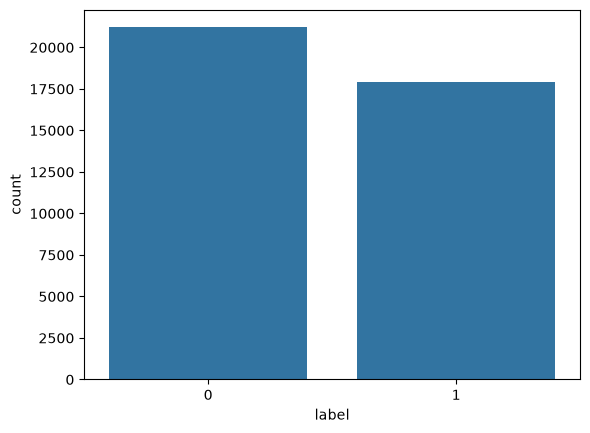

In [59]:
sns.countplot(x=df['label'])

In [60]:
stop_words = set(stopwords.words('english'))

def count_stopwords(text):
    text = text.lower()

    text = text.strip()

    text = text.split()

    words = len([word for word in text if word in stop_words])
    return words

In [61]:
text = df['detail_text'].map(count_stopwords)

In [63]:
text

0         284
1         235
2         186
3         143
4         336
         ... 
39100     521
39101    1817
39102      59
39103    1454
39104     388
Name: detail_text, Length: 39105, dtype: int64

<Axes: xlabel='detail_text', ylabel='Count'>

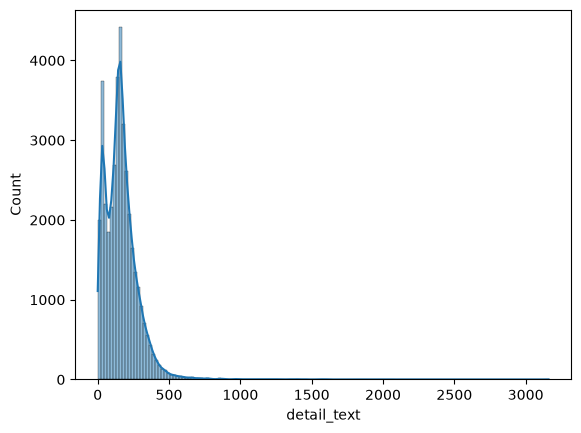

In [67]:
sns.histplot(text,bins=150, kde=True)

Text(0.5, 0, 'length of stopwords')

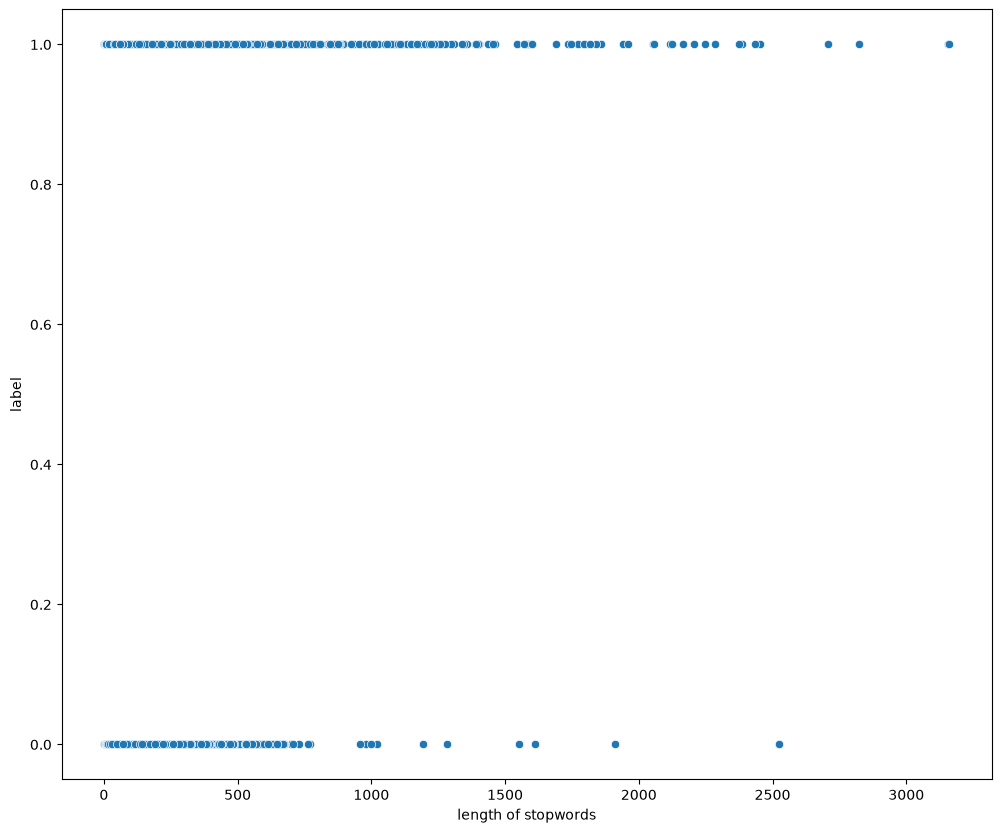

In [70]:
plt.figure(figsize=(12,10))
sns.scatterplot(x=text, y=df['label'])
plt.xlabel("length of stopwords")

In [72]:
from collections import Counter


def extract_stopwords(text):
    all_stopwords = []
    for comment in text:
        for word in comment.split():
            if word in stop_words:
                all_stopwords.append(word)

    return all_stopwords

text_stopwords = extract_stopwords(df['detail_text'])


In [73]:
text_most_common_stop_words = pd.DataFrame(Counter(text_stopwords).most_common(25), columns=['stop_words','count'])

Text(0, 0.5, 'text_most_common_stop_words')

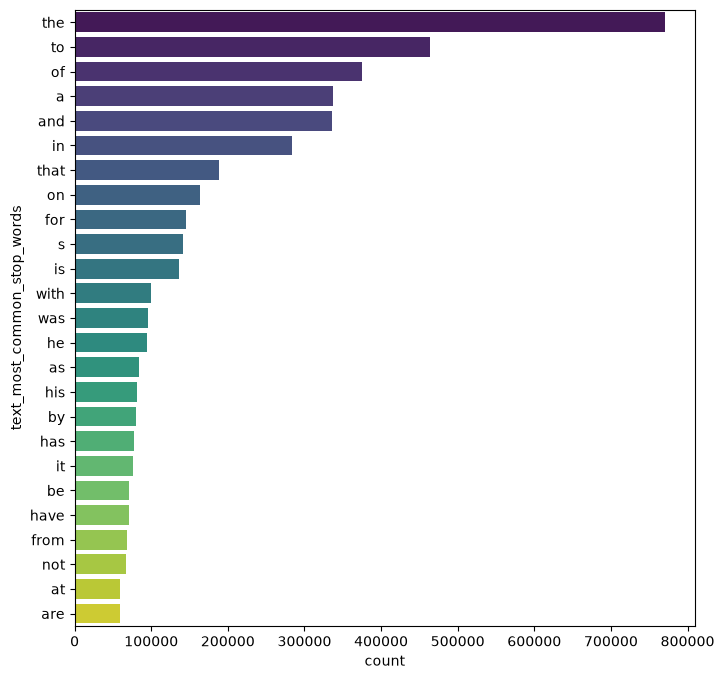

In [74]:
plt.figure(figsize=(8,8))
sns.barplot(x=text_most_common_stop_words['count'], y=text_most_common_stop_words['stop_words'], palette="viridis")
plt.ylabel("text_most_common_stop_words")

In [75]:
import re

def extract_all_words(text):
    all_words = []

    for comment in text:
        for word in comment.split():

            word = word.lower()
            word = re.sub(r'[^a-zA-Z\s]', '', word)
            word = word.strip()
            
            if word not in stop_words and word != "":
                all_words.append(word)

    return all_words

In [76]:
all_words = extract_all_words(df['detail_text'])
all_words

['us',
 'budget',
 'fight',
 'looms',
 'republicans',
 'flip',
 'fiscal',
 'script',
 'washington',
 'reuters',
 'head',
 'conservative',
 'republican',
 'faction',
 'us',
 'congress',
 'voted',
 'month',
 'huge',
 'expansion',
 'national',
 'debt',
 'pay',
 'tax',
 'cuts',
 'called',
 'fiscal',
 'conservative',
 'sunday',
 'urged',
 'budget',
 'restraint',
 'keeping',
 'sharp',
 'pivot',
 'way',
 'among',
 'republicans',
 'us',
 'representative',
 'mark',
 'meadows',
 'speaking',
 'cbs',
 'face',
 'nation',
 'drew',
 'hard',
 'line',
 'federal',
 'spending',
 'lawmakers',
 'bracing',
 'battle',
 'january',
 'return',
 'holidays',
 'wednesday',
 'lawmakers',
 'begin',
 'trying',
 'pass',
 'federal',
 'budget',
 'fight',
 'likely',
 'linked',
 'issues',
 'immigration',
 'policy',
 'even',
 'november',
 'congressional',
 'election',
 'campaigns',
 'approach',
 'republicans',
 'seek',
 'keep',
 'control',
 'congress',
 'president',
 'donald',
 'trump',
 'republicans',
 'want',
 'big',
 'b

In [77]:
top_30_most_used_words = pd.DataFrame(Counter(all_words).most_common(30), columns=['stop_words','count'])

Text(0, 0.5, 'Most common words')

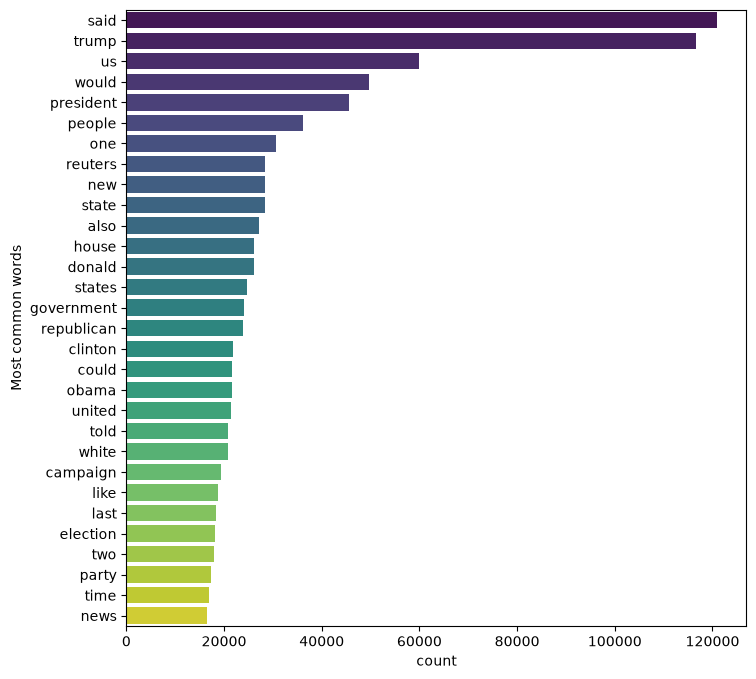

In [78]:
plt.figure(figsize=(8,8))
sns.barplot(x=top_30_most_used_words['count'], y=top_30_most_used_words['stop_words'], palette="viridis")
plt.ylabel("Most common words")

In [79]:
from sklearn.feature_extraction.text import CountVectorizer

# Create a function to extract the top 25 bigrams
def get_top_ngrams(corpus, n=None):
    vec = CountVectorizer(ngram_range=(2, 2), stop_words='english').fit(corpus)
    bag_of_words = vec.transform(corpus)
    sum_words = bag_of_words.sum(axis=0)
    words_freq = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
    words_freq = sorted(words_freq, key=lambda x: x[1], reverse=True)
    return words_freq[:n]

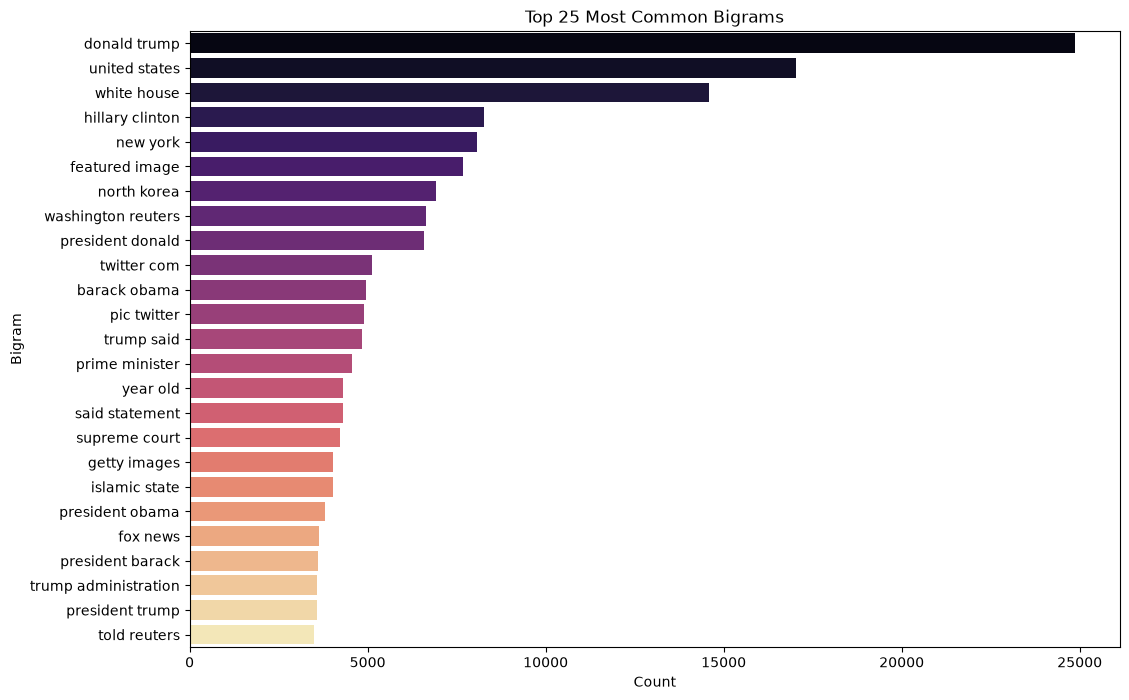

In [80]:
top_25_biagrams = get_top_ngrams(df['detail_text'],25)

top_25_bigrams_df = pd.DataFrame(top_25_biagrams, columns=['bigram', 'count'])

# Plot the countplot for the top 25 bigrams
plt.figure(figsize=(12, 8))
sns.barplot(data=top_25_bigrams_df, x='count', y='bigram', palette='magma')
plt.title('Top 25 Most Common Bigrams')
plt.xlabel('Count')
plt.ylabel('Bigram')
plt.show()

In [81]:
def get_top_trigrams(corpus, n=None):
    vec = CountVectorizer(ngram_range=(3, 3), stop_words='english').fit(corpus)
    bag_of_words = vec.transform(corpus)
    sum_words = bag_of_words.sum(axis=0)
    words_freq = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
    words_freq = sorted(words_freq, key=lambda x: x[1], reverse=True)
    return words_freq[:n]

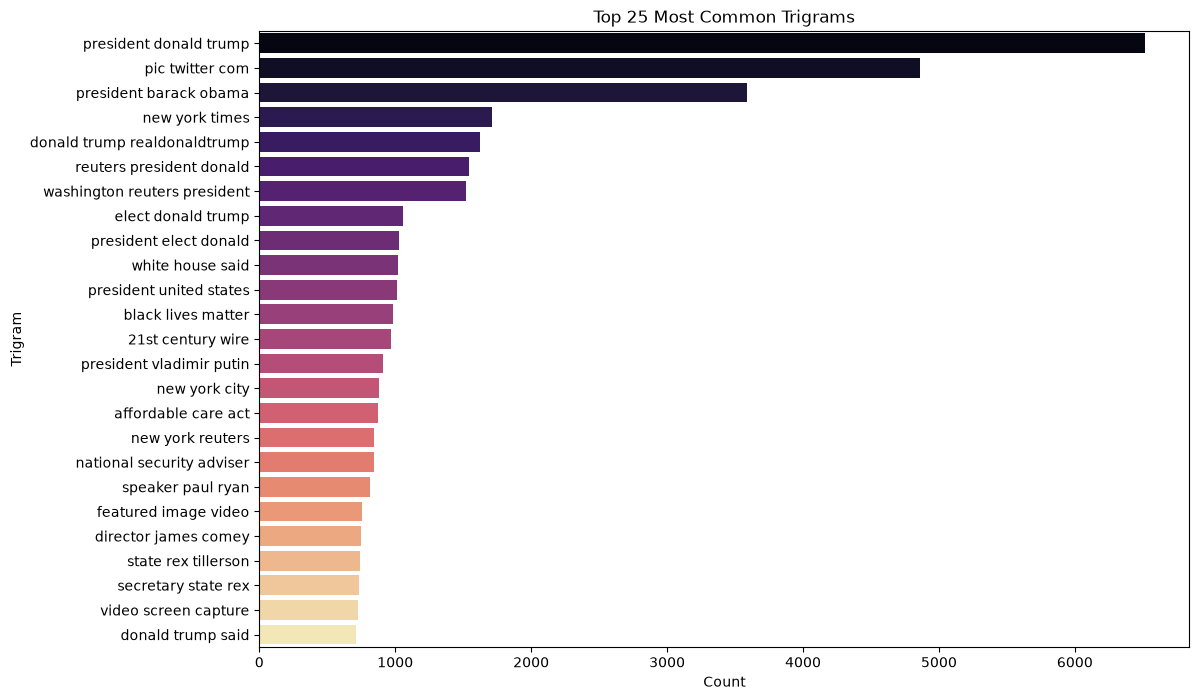

In [83]:
top_25_trigrams = get_top_trigrams(df['detail_text'],25)

top_25_trigrams_df = pd.DataFrame(top_25_trigrams, columns=['trigram', 'count'])

# Plot the countplot for the top 25 bigrams
plt.figure(figsize=(12, 8))
sns.barplot(data=top_25_trigrams_df, x='count', y='trigram', palette='magma')
plt.title('Top 25 Most Common Trigrams')
plt.xlabel('Count')
plt.ylabel('Trigram')
plt.show()

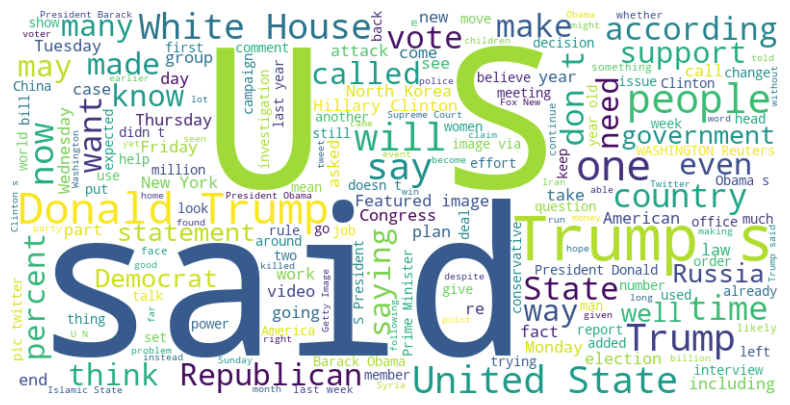

In [84]:
from wordcloud import WordCloud

def plot_word_cloud(text):
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(' '.join(text))
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis("off")
    plt.show()

plot_word_cloud(df['detail_text'])

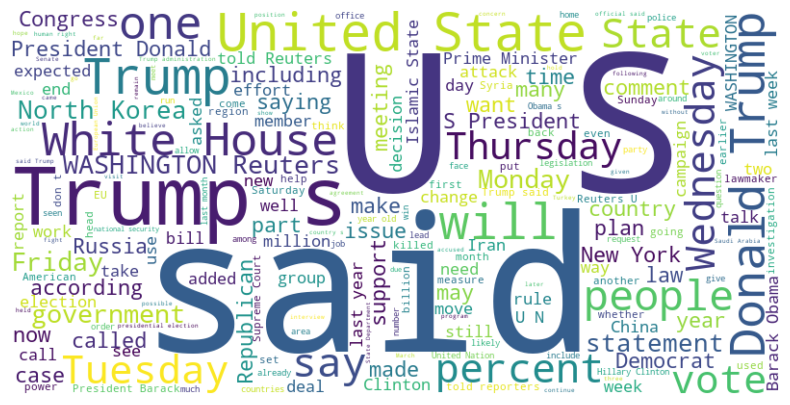

In [85]:
plot_word_cloud(df[df['label'] == 0]['detail_text'])

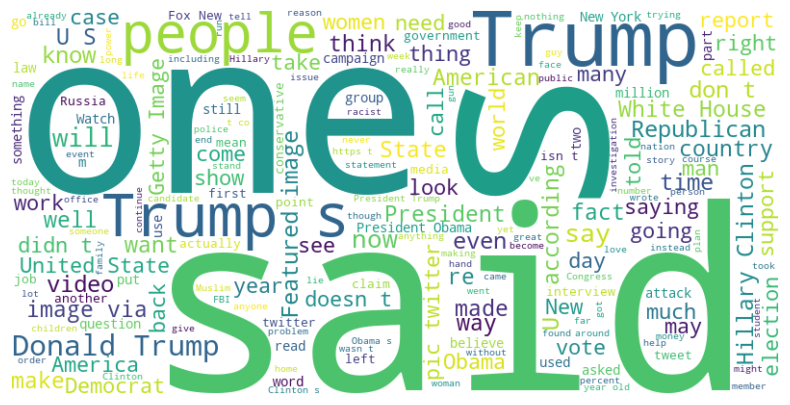

In [86]:
plot_word_cloud(df[df['label'] == 1]['detail_text'])

In [88]:
df.to_csv("../final_df.csv",index=False)